# Task 2(a) — ARPDAU is falling

**Business question:** Overall ARPDAU falls from the first 30 days to the last 30 days, while country-tier ARPDAU is flat or improving.

This notebook deliberately **does not use Task 1 output files as the source of truth**. Task 1 findings are used as a reference for relevant data-quality checks; Task 2 re-checks those issues directly against `analysis.duckdb` before calculating the deep dive.

**Analysis window:** 2026-01-01 to 2026-04-30.


In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
SQL_DIR = PROJECT / "sql" / "task-2"
OUTPUT_DIR = PROJECT / "output" / "task-2"
CHART_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

DB_PATH = PROJECT / "analysis.duckdb"
con = duckdb.connect(str(DB_PATH))

print("Project:", PROJECT)
print("Database:", DB_PATH)
print("Task 2 output:", OUTPUT_DIR)


Project: v:\2026\Analytics Intern Assignment
Database: v:\2026\Analytics Intern Assignment\analysis.duckdb
Task 2 output: v:\2026\Analytics Intern Assignment\output\task-2


## 1. Data-quality checks relevant to Task 2

Task 1 identified production-data issues such as duplicate purchase IDs, purchases before install, events outside the analysis window, and telemetry gaps. For this deep dive, we re-check the issues that could affect revenue, DAU, tier assignment, or period comparisons.

We do not silently deduplicate purchase IDs because repeated IDs have to be inspected before deciding whether they represent duplicate transactions.


In [2]:
dq = con.execute("""
SELECT 'player_profile duplicate device_id' AS check_name, COUNT(*) AS issue_count
FROM (SELECT device_id FROM player_profile GROUP BY device_id HAVING COUNT(*) > 1)
UNION ALL
SELECT 'player_day duplicate player-day key', COUNT(*)
FROM (SELECT device_id, activity_date FROM player_day GROUP BY 1,2 HAVING COUNT(*) > 1)
UNION ALL
SELECT 'purchase IDs appearing more than once', COUNT(*)
FROM (SELECT purchase_id FROM purchase GROUP BY purchase_id HAVING COUNT(*) > 1)
UNION ALL
SELECT 'purchases before recorded install', COUNT(*)
FROM purchase p JOIN player_profile pp USING(device_id)
WHERE CAST(p.event_ts AS DATE) < CAST(pp.install_date AS DATE)
UNION ALL
SELECT 'purchase rows outside assignment window', COUNT(*)
FROM purchase
WHERE CAST(event_ts AS DATE) < DATE '2026-01-01' OR CAST(event_ts AS DATE) >= DATE '2026-05-01'
UNION ALL
SELECT 'player-day rows outside assignment window', COUNT(*)
FROM player_day
WHERE activity_date < 20260101 OR activity_date > 20260430
UNION ALL
SELECT 'player-day rows with missing country tier', COUNT(*)
FROM player_day pd JOIN player_profile pp USING(device_id)
WHERE pp.country_tier IS NULL
""").df()
dq.to_csv(TABLE_DIR / "task2_data_quality_checks.csv", index=False)
display(dq)


,check_name,issue_count
0,player_profile duplicate device_id,0
1,player_day duplicate player-day key,0
2,purchase IDs appearing more than once,122
3,purchases before recorded install,114
4,purchase rows outside assignment window,0
5,player-day rows outside assignment window,0
6,player-day rows with missing country tier,0


### Quality-treatment decisions

- **Assignment window:** restrict Task 2 metrics to 2026-01-01 through 2026-04-30.
- **Known players:** join telemetry to `player_profile` so tier and player identity are available consistently.
- **Duplicate purchase IDs:** do not deduplicate automatically; use recorded transaction rows and flag the issue.
- **Purchases before install:** keep them in the primary recorded-revenue analysis so the main metric remains reproducible from the telemetry; run a sensitivity check excluding them.
- **Missing country tier:** check explicitly; rows with missing tier cannot contribute to tier decomposition.


## 2. Task 1 output cross-check (reference only)

If Task 1 has already been run, its daily-health output can be compared with Task 2's independently calculated metric. This is a **sanity check, not an input dependency**.


In [3]:
task1_daily = PROJECT / "output" / "tables" / "daily_health.csv"
if task1_daily.exists():
    ref = pd.read_csv(task1_daily)
    print("Task 1 daily-health output found:", task1_daily)
    display(ref.head())
    print("Task 2 remains independently calculated from analysis.duckdb.")
else:
    print("Task 1 output file not found; continuing because Task 2 does not depend on it.")


Task 1 output file not found; continuing because Task 2 does not depend on it.


## 3. Overall ARPDAU

ARPDAU is calculated as total in-app purchase revenue divided by total active player-days for the period.


In [4]:
overall = con.execute((SQL_DIR / "2a_overall_arpdau.sql").read_text()).df()
overall["change_usd"] = overall["arpdau"].diff()
overall["change_pct"] = overall["arpdau"].pct_change() * 100
overall.to_csv(TABLE_DIR / "overall_arpdau.csv", index=False)
display(overall)


,period,active_player_days,revenue,arpdau,change_usd,change_pct
0,First 30 Days,82381.0,28926.91,0.351136,NaN,NaN
1,Last 30 Days,282781.0,82925.47,0.293250,-0.057886,-16.485337


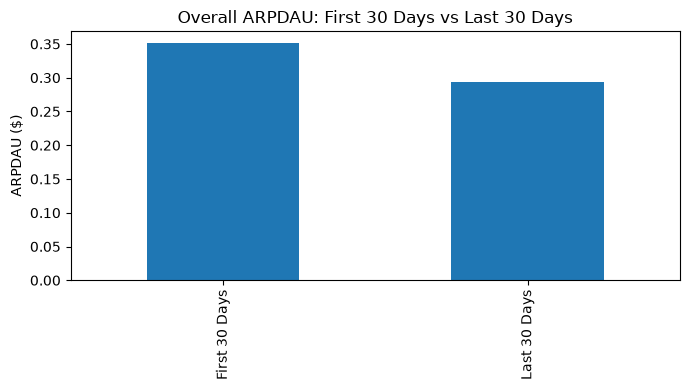

In [5]:
ax = overall.plot(x="period", y="arpdau", kind="bar", legend=False, figsize=(7,4))
ax.set_ylabel("ARPDAU ($)")
ax.set_xlabel("")
ax.set_title("Overall ARPDAU: First 30 Days vs Last 30 Days")
plt.tight_layout()
plt.savefig(CHART_DIR / "overall_arpdau_comparison.png", dpi=180)
plt.show()


## 4. ARPDAU by country tier

The assignment specifically recommends country-tier analysis because individual countries have too few transactions for a stable ARPDAU trend.


In [6]:
tier = con.execute((SQL_DIR / "2b_tier_arpdau.sql").read_text()).df()
pivot = tier.pivot(index="country_tier", columns="period", values="arpdau")
pivot["change_pct"] = (pivot["Last 30 Days"] / pivot["First 30 Days"] - 1) * 100
tier.to_csv(TABLE_DIR / "tier_arpdau.csv", index=False)
pivot.to_csv(TABLE_DIR / "tier_arpdau_change.csv")
display(pivot)


period,First 30 Days,Last 30 Days,change_pct
country_tier,,,
1,0.518601,0.546297,5.340549
2,0.362648,0.402063,10.868762
3,0.231643,0.263214,13.629386
4,0.154813,0.155695,0.569784


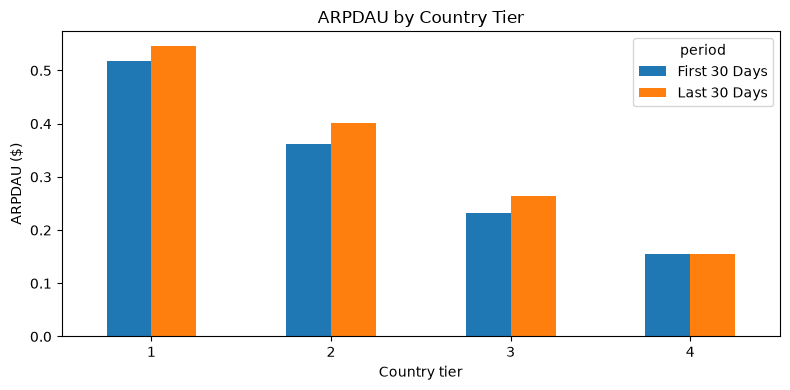

In [7]:
plot_df = pivot[["First 30 Days", "Last 30 Days"]]
ax = plot_df.plot(kind="bar", figsize=(8,4))
ax.set_ylabel("ARPDAU ($)")
ax.set_xlabel("Country tier")
ax.set_title("ARPDAU by Country Tier")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "tier_arpdau_comparison.png", dpi=180)
plt.show()


## 5. Country-tier mix

Next we test whether the active-player mix shifted toward tiers with lower ARPDAU.


In [8]:
mix = con.execute((SQL_DIR / "2c_mix_effect.sql").read_text()).df()
mix.to_csv(TABLE_DIR / "tier_mix.csv", index=False)
display(mix)


,country_tier,first_active_player_days,last_active_player_days,first_dau_mix,last_dau_mix,mix_change
0,1,28397.0,57821.0,0.344703,0.204473,-0.140231
1,2,21469.0,43988.0,0.260606,0.155555,-0.105051
2,3,17972.0,50927.0,0.218157,0.180093,-0.038064
3,4,14543.0,130045.0,0.176533,0.459879,0.283345


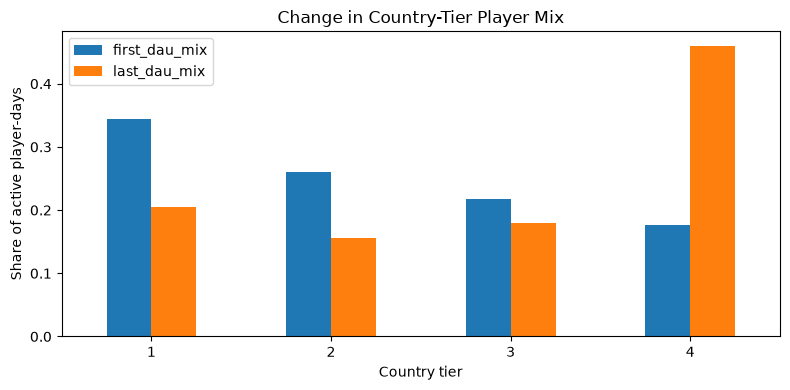

In [9]:
mix_plot = mix.set_index("country_tier")[["first_dau_mix", "last_dau_mix"]]
ax = mix_plot.plot(kind="bar", figsize=(8,4))
ax.set_ylabel("Share of active player-days")
ax.set_xlabel("Country tier")
ax.set_title("Change in Country-Tier Player Mix")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "tier_mix_comparison.png", dpi=180)
plt.show()


## 6. Mix vs within-tier contribution

The decomposition uses: **overall ARPDAU = Σ(tier mix × tier ARPDAU)**.

The counterfactual holds first-period tier ARPDAU fixed and applies the last-period player mix. The difference from the first-period overall ARPDAU is the mix effect; the remaining movement is the within-tier effect.


In [10]:
decomp = con.execute((SQL_DIR / "2d_contribution_analysis.sql").read_text()).df()
decomp.to_csv(TABLE_DIR / "arpdau_decomposition.csv", index=False)
display(decomp)


,first_arpdau,last_arpdau,total_change,mix_effect,within_tier_effect,share_of_total_change_from_mix
0,0.351136,0.29325,-0.057886,-0.075772,0.017886,1.308984


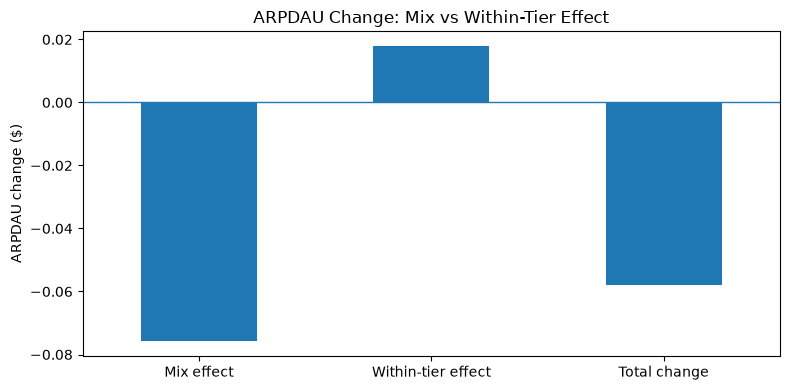

In [11]:
d = decomp.iloc[0]
summary = pd.DataFrame({
    "component": ["Mix effect", "Within-tier effect", "Total change"],
    "arpdau_change": [d["mix_effect"], d["within_tier_effect"], d["total_change"]]
})
summary.to_csv(TABLE_DIR / "arpdau_decomposition_components.csv", index=False)
ax = summary.plot(x="component", y="arpdau_change", kind="bar", legend=False, figsize=(8,4))
ax.axhline(0, linewidth=1)
ax.set_ylabel("ARPDAU change ($)")
ax.set_xlabel("")
ax.set_title("ARPDAU Change: Mix vs Within-Tier Effect")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "arpdau_decomposition.png", dpi=180)
plt.show()


## 7. Data-quality sensitivity: purchases before install

Task 1 found a small number of purchases before the recorded install date. Because this can affect revenue-based metrics, we check whether excluding those records changes the conclusion.


In [12]:
sensitivity = con.execute("""
WITH active AS (
    SELECT STRPTIME(CAST(activity_date AS VARCHAR), '%Y%m%d')::DATE AS activity_date,
           COUNT(DISTINCT device_id) AS dau
    FROM player_day
    JOIN player_profile USING(device_id)
    WHERE activity_date BETWEEN 20260101 AND 20260430
    GROUP BY 1
), revenue AS (
    SELECT CAST(p.event_ts AS DATE) AS activity_date,
           SUM(p.usd_amount) AS revenue_recorded,
           SUM(CASE WHEN CAST(p.event_ts AS DATE) >= CAST(pp.install_date AS DATE)
                    THEN p.usd_amount ELSE 0 END) AS revenue_post_install
    FROM purchase p
    JOIN player_profile pp USING(device_id)
    WHERE CAST(p.event_ts AS DATE) >= DATE '2026-01-01'
      AND CAST(p.event_ts AS DATE) < DATE '2026-05-01'
    GROUP BY 1
), daily AS (
    SELECT a.activity_date, a.dau,
           COALESCE(r.revenue_recorded,0) AS revenue_recorded,
           COALESCE(r.revenue_post_install,0) AS revenue_post_install
    FROM active a LEFT JOIN revenue r USING(activity_date)
), periods AS (
    SELECT 'First 30 Days' AS period, * FROM daily WHERE activity_date BETWEEN DATE '2026-01-01' AND DATE '2026-01-30'
    UNION ALL
    SELECT 'Last 30 Days' AS period, * FROM daily WHERE activity_date BETWEEN DATE '2026-04-01' AND DATE '2026-04-30'
)
SELECT period,
       SUM(revenue_recorded) / SUM(dau) AS recorded_arpdau,
       SUM(revenue_post_install) / SUM(dau) AS post_install_arpdau
FROM periods
GROUP BY period
ORDER BY CASE period WHEN 'First 30 Days' THEN 1 ELSE 2 END
""").df()
sensitivity.to_csv(TABLE_DIR / "arpdau_quality_sensitivity.csv", index=False)
display(sensitivity)


,period,recorded_arpdau,post_install_arpdau
0,First 30 Days,0.351136,0.349754
1,Last 30 Days,0.293250,0.290935


## 8. Findings and business interpretation

Use the calculated outputs above rather than assuming the answer before running the notebook.

### Decision logic
- If all tiers are stable/improving and the mix shifts toward lower-ARPDAU tiers, the aggregate decline is primarily a composition effect.
- If a tier materially deteriorates, investigate within-tier monetization for that tier.
- A descriptive decomposition does not establish causality; acquisition mix, cohort mix, or other operational changes may be upstream drivers.

### Business action
If the observed pattern is confirmed, the next investigation should focus on **why the active-player mix shifted**, especially the large movement in Tier 4, rather than applying a blanket monetization fix to the whole game.

The dataset does not include marketing spend, so it cannot determine acquisition ROI or the financial cause of the mix shift. Those inputs would be needed for the next business decision.


## 9. Task 2 output files

All Task 2 tables are saved under `output/task-2/tables/` and all charts under `output/task-2/charts/`.


In [13]:
con.close()
print("Task 2 complete. Outputs saved to:", OUTPUT_DIR)


Task 2 complete. Outputs saved to: v:\2026\Analytics Intern Assignment\output\task-2
